# MLB Data: Effectiveness GLMM

## Libraries

In [1]:
# Imports

# Data manipulation
import numpy as np
import pandas as pd 
# Data visualization
import matplotlib.pyplot as plt 
import seaborn as sns
# Logistic regression
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Binomial Bayes - Random Int Model
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
# Comparison metrics
from sklearn.metrics import roc_auc_score, log_loss

## Data

In [2]:
df = pd.read_csv('FullData_V1.csv')

<p> Keep the bare bones of the data. As we go on we will limit step by step, the variables we need.

In [3]:
keep_vars = [
    # Identifiers
    'pitcher', 'player_name', 'pitching_team', 'game_pk', 'game_date', 'game_type',

    # Outcome Source
    'description',

    # predictors
    'release_speed', 'pitch_type', 'balls', 'strikes', 'stand', 'p_throws',
    'zone', 'outs_when_up', 'base_state_label', 'outing_pitch_count', 'pitcher_role'
]

# Safety Check
missing_cols = [c for c in keep_vars if c not in df.columns]
print("Not in df: ", missing_cols)

# New working df (will be further altered)
wdf = df[keep_vars].copy()
print(wdf.shape)

Not in df:  []
(14096, 18)


<p> Now we want to create our dependent variable (wiff) to measure effectiveness. Wiff is only valid where a swing occurs, so we are gonna use a fuller data set to create/transform variables, and then copy swings only when needed.

In [4]:
bunt_desc    = {'foul_bunt', 'missed_bunt', 'bunt_foul_tip'}
whiff_desc   = {'swinging_strike', 'swinging_strike_blocked', 'foul_tip'}
contact_desc = {'foul', 'hit_into_play'}

print(wdf['description'].isin(bunt_desc).sum(), "bunt rows")

# Create our working response variable - feature dataset
non_bunt_pitches = wdf[~wdf['description'].isin(bunt_desc)].copy()
non_bunt_pitches['swing'] = non_bunt_pitches['description'].isin(whiff_desc | contact_desc)
non_bunt_pitches['whiff'] = non_bunt_pitches['description'].isin(whiff_desc).astype(int)

# Wiff is only defined when a swing occurs - model dataset
swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()
print(len(non_bunt_pitches), len(swings_only), swings_only['whiff'].mean())

33 bunt rows
14063 6842 0.278865828705057


In [5]:
# Quick Checks - to be removed for submission
swings_per_pitcher = swings_only.groupby('pitcher').size()
# swings per pitcher, all teams
print(swings_per_pitcher.describe())                            

jays = swings_only[swings_only['pitching_team'] == 'TOR']
# swings per Jays pitcher
print(jays.groupby('player_name').size().sort_values()) 

# rare pitch types
print(swings_only.groupby('pitch_type')['whiff'].agg(['size', 'mean'])) 
# missingness  
print(swings_only.isna().mean().sort_values(ascending=False).head(10))    
# velocity spread
print(swings_only.groupby(['pitcher', 'pitch_type'])['release_speed'].std().describe())

count    143.000000
mean      47.846154
std       47.025661
min        1.000000
25%       16.500000
50%       33.000000
75%       60.000000
max      259.000000
dtype: float64
player_name
Bruihl, Justin             5
Rodríguez, Yariel         15
Nance, Tommy              17
Little, Brendon           36
Fisher, Braydon           56
Bassitt, Chris            58
Lauer, Eric               62
Fluharty, Mason           73
Domínguez, Seranthony     78
Hoffman, Jeff             96
Scherzer, Max            117
Varland, Louis           117
Bieber, Shane            149
Yesavage, Trey           200
Gausman, Kevin           217
dtype: int64
            size      mean
pitch_type                
CH           541  0.365989
CU           436  0.350917
FC           417  0.223022
FF          2347  0.224542
FS           505  0.417822
KC           158  0.417722
SI           890  0.153933
SL          1182  0.333333
ST           337  0.353116
SV            29  0.344828
pitcher          0.0
player_name      0.0

<p> After some checks we want to have better predictors in the model. Speed alone doesn't account for pitch type. Speed and pitch type together ignore the fact that some pitchers might differ then their own normals.

In [6]:
# Merge a rare SV (slurve) pitch into curveball
non_bunt_pitches['pitch_type'] = non_bunt_pitches['pitch_type'].replace({'SV': 'CU'})

# Treat Jays pitchers as an indicator
non_bunt_pitches['is_jays'] = (non_bunt_pitches['pitching_team'] == 'TOR').astype(int)

# Same-handed matchup (1 = batter and pitcher hands match)
non_bunt_pitches['same_hand'] = (non_bunt_pitches['stand'] == non_bunt_pitches['p_throws']).astype(int)

# Pitch count in units of 10 pitches (coefficient = effect per 10 pitches)
non_bunt_pitches['pc10'] = non_bunt_pitches['outing_pitch_count'] / 10

# Outing identifier (one pitcher in one game)
non_bunt_pitches['outing_id'] = (non_bunt_pitches['game_pk'].astype(str) + '_'
                                 + non_bunt_pitches['pitcher'].astype(str))

# Base state as a categorical label
non_bunt_pitches['base_state_label'] = non_bunt_pitches['base_state_label'].astype(str)

# Average release speed of pitch type across ALL pitchers
non_bunt_pitches['pt_mean'] = non_bunt_pitches.groupby('pitch_type')['release_speed'].transform('mean')
# The within pitcher release speed average (e.g Guasmans fastball avg)
non_bunt_pitches['pp_mean'] = non_bunt_pitches.groupby(['pitcher', 'pitch_type'])['release_speed'].transform('mean')
# The numbr of pitches that make up the pp_mean (reliability metric for some less common pitchers)
non_bunt_pitches['pp_n'] = non_bunt_pitches.groupby(['pitcher', 'pitch_type'])['release_speed'].transform('size')

# The difference between the pitchers individual average
non_bunt_pitches['velo_within']  = non_bunt_pitches['release_speed'] - non_bunt_pitches['pp_mean']
# The difference between the postseason average
non_bunt_pitches['velo_between'] = non_bunt_pitches['pp_mean'] - non_bunt_pitches['pt_mean']

# Swing only with new vars
swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()


In [7]:
# More checks
print(swings_only['pitch_type'].value_counts())
print(swings_only[['velo_within', 'velo_between']].describe())
print(swings_only['pp_n'].describe())
print(swings_only.groupby('is_jays')['velo_between'].mean())

pitch_type
FF    2347
SL    1182
SI     890
CH     541
FS     505
CU     465
FC     417
ST     337
KC     158
Name: count, dtype: int64
       velo_within  velo_between
count  6842.000000   6842.000000
mean      0.051038      0.018516
std       1.021266      2.677328
min      -7.558333    -10.138238
25%      -0.598082     -1.814628
50%       0.069007      0.014450
75%       0.711111      1.749919
max       4.504545     11.507836
count    6842.000000
mean       60.976907
std        46.991131
min         1.000000
25%        23.000000
50%        48.000000
75%        84.000000
max       194.000000
Name: pp_n, dtype: float64
is_jays
0    0.154066
1   -0.561544
Name: velo_between, dtype: float64


In [8]:
# Round the means - too many trailing decimals
cols_to_round = ['pt_mean', 'pp_mean', 'velo_within', 'velo_between']
non_bunt_pitches[cols_to_round] = non_bunt_pitches[cols_to_round].round(4)

swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()

In [9]:
# Check - to be removed for submission
print(swings_only.groupby('pitcher')['pitcher_role'].nunique().value_counts())   # 1 = fixed per pitcher
print(pd.crosstab(swings_only['is_jays'], swings_only['pitcher_role'], normalize='index'))
print(swings_only.groupby('pitcher_role')['whiff'].agg(['size', 'mean']))
print(swings_only.groupby('pitcher_role')['release_speed'].mean())

pitcher_role
1    124
2     19
Name: count, dtype: int64
pitcher_role  reliever   starter
is_jays                         
0             0.509556  0.490444
1             0.482253  0.517747
              size      mean
pitcher_role                
reliever      3451  0.252680
starter       3391  0.305515
pitcher_role
reliever    91.290872
starter     90.412651
Name: release_speed, dtype: float64


In [10]:
model_cols = ['whiff', 'pitcher', 'outing_id', 'is_jays', 'pc10', 'velo_within', 'velo_between',
              'pitch_type', 'balls', 'strikes', 'same_hand', 'zone', 'pitcher_role',
              'outs_when_up', 'base_state_label']
model_df = swings_only[model_cols].copy()
print(model_df.shape, model_df.isna().sum().sum())

(6842, 15) 0


In [11]:
# Checks on new variables - to be removed for submission
print(swings_only['outing_pitch_count'].describe())
print(swings_only['outing_id'].nunique(), 'outings')

for c in ['base_state_label', 'outs_when_up', 'zone']:
    print(swings_only.groupby(c)['whiff'].agg(['size', 'mean']))

count    6842.000000
mean       27.983338
std        24.663222
min         1.000000
25%         9.000000
50%        19.000000
75%        42.000000
max       116.000000
Name: outing_pitch_count, dtype: float64
475 outings
                  size      mean
base_state_label                
1st & 2nd          516  0.286822
1st & 3rd          187  0.213904
1st only          1269  0.256107
2nd & 3rd          113  0.230088
2nd only           470  0.257447
3rd only           118  0.254237
Empty             3946  0.292955
Loaded             223  0.278027
              size      mean
outs_when_up                
0             2368  0.268581
1             2326  0.265692
2             2148  0.304469
      size      mean
zone                
1      373  0.222520
2      586  0.215017
3      344  0.252907
4      562  0.119217
5      765  0.132026
6      587  0.183986
7      392  0.260204
8      633  0.195893
9      445  0.283146
11     379  0.306069
12     367  0.329700
13     606  0.462046
14     803

is_jays     0    1
pc_bin            
1-15     2359  588
16-30    1243  268
31-45     691  135
46-60     497  131
61-75     382  105
76-90     242   60
91+       132    9


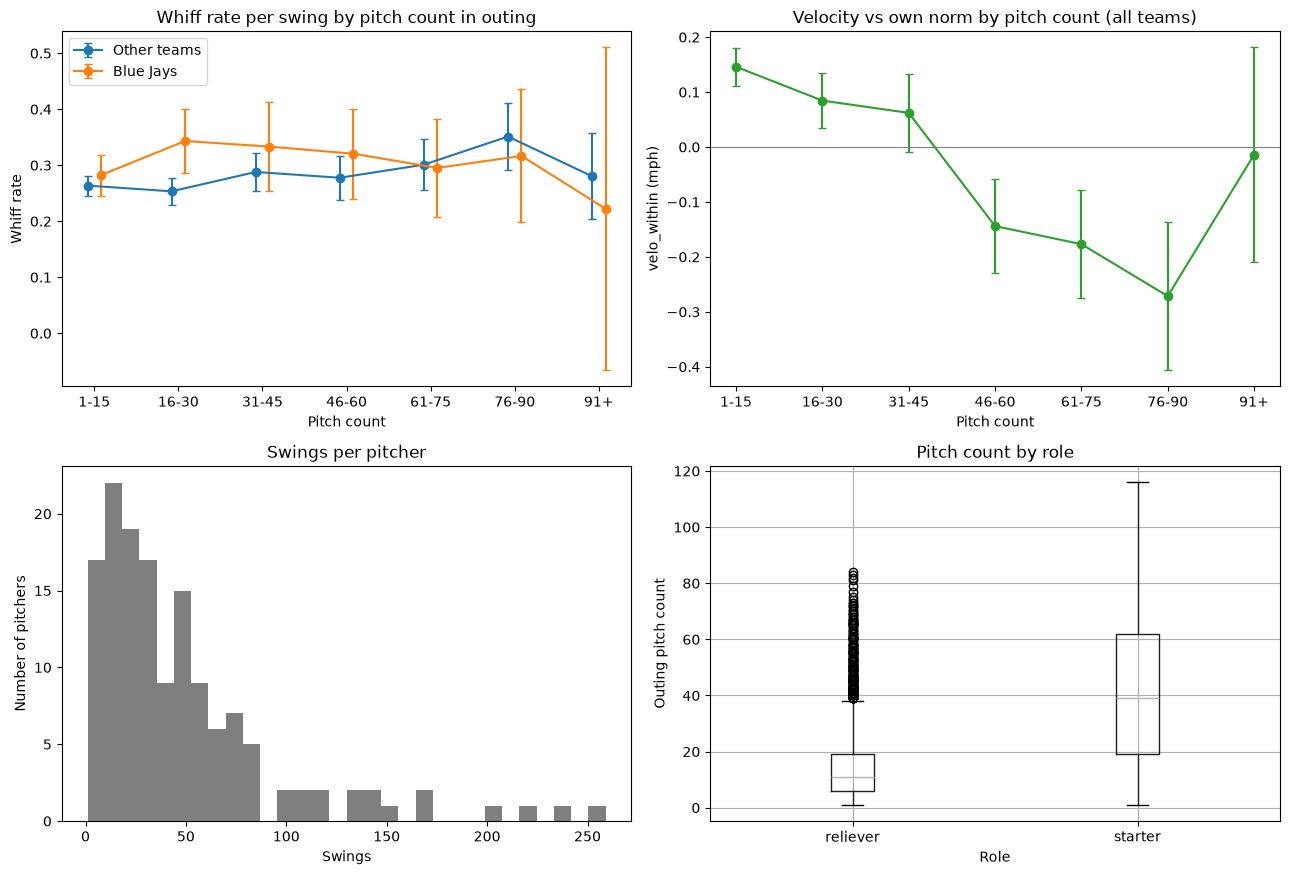

In [12]:
edges  = [0, 15, 30, 45, 60, 75, 90, 200]
labels = ['1-15', '16-30', '31-45', '46-60', '61-75', '76-90', '91+']
swings_only['pc_bin'] = pd.cut(swings_only['outing_pitch_count'], edges, labels=labels)

# Swings per bin: check for thin bins
print(swings_only.groupby(['is_jays', 'pc_bin'], observed=True).size().unstack(0))

def binned(frame, col):
    g = frame.groupby('pc_bin', observed=True)[col].agg(['mean', 'count', 'std']).reindex(labels)
    g['se'] = g['std'] / np.sqrt(g['count'])
    return g

x = np.arange(len(labels))
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Whiff rate vs pitch count, Jays vs others
for flag, name, off in [(0, 'Other teams', -0.08), (1, 'Blue Jays', 0.08)]:
    g = binned(swings_only[swings_only['is_jays'] == flag], 'whiff')
    ax[0, 0].errorbar(x + off, g['mean'], yerr=1.96 * g['se'], marker='o', capsize=3, label=name)
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(labels)
ax[0, 0].set(title='Whiff rate per swing by pitch count in outing', xlabel='Pitch count', ylabel='Whiff rate')
ax[0, 0].legend()

# 2. Velocity vs own norm by pitch count
g = binned(swings_only, 'velo_within')
ax[0, 1].errorbar(x, g['mean'], yerr=1.96 * g['se'], marker='o', capsize=3, color='tab:green')
ax[0, 1].axhline(0, color='grey', lw=0.8)
ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(labels)
ax[0, 1].set(title='Velocity vs own norm by pitch count (all teams)', xlabel='Pitch count', ylabel='velo_within (mph)')

# 3. Swings per pitcher
ax[1, 0].hist(swings_only.groupby('pitcher').size(), bins=30, color='tab:grey')
ax[1, 0].set(title='Swings per pitcher', xlabel='Swings', ylabel='Number of pitchers')

# 4. Pitch count by role
swings_only.boxplot(column='outing_pitch_count', by='pitcher_role', ax=ax[1, 1])
ax[1, 1].set(title='Pitch count by role', xlabel='Role', ylabel='Outing pitch count')

fig.suptitle('')
plt.tight_layout()
plt.show()

In [13]:
def base_group(s):
    if s == 'Empty':
        return 'Empty'
    if s == '1st only':
        return 'First only'
    return 'Scoring position'

model_df['base_group'] = swings_only['base_state_label'].map(base_group)
print(model_df['base_group'].value_counts())

base_group
Empty               3946
Scoring position    1627
First only          1269
Name: count, dtype: int64


<p> Use a comparison logistic regression without fixed effects to compare the later model to.

In [14]:
f_base = ('whiff ~ C(pitch_type, Treatment("FF")) + C(balls) + C(strikes) + same_hand '
          '+ C(zone) + C(pitcher_role) + C(outs_when_up) + C(base_group, Treatment("Empty"))')
f_m0 = f_base + ' + pc10 * is_jays + velo_within + velo_between'

In [17]:
res0 = smf.logit(f_m0, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)

ci = res0.conf_int()
tab0 = pd.DataFrame({'OR': np.exp(res0.params), 'lo': np.exp(ci[0]),
                     'hi': np.exp(ci[1]), 'p': res0.pvalues})
tab0['Significant?'] = np.where(tab0['p'] < 0.05, 'Yes', 'No')

tab0.index = (tab0.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                        .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                        .str.replace(']', '', regex=False))

hide = ('Intercept', 'C(zone)', 'C(balls)', 'C(strikes)', 'C(outs_when_up)',
        'C(pitcher_role)', 'same_hand')
rows = [i for i in tab0.index if not i.startswith(hide)]
print(tab0.loc[rows].round(3))

                           OR     lo     hi      p Significant?
vs FF: CH               1.484  1.080  2.040  0.015          Yes
vs FF: CU               1.330  1.005  1.761  0.046          Yes
vs FF: FC               0.855  0.611  1.197  0.362           No
vs FF: FS               1.911  1.317  2.773  0.001          Yes
vs FF: KC               1.659  1.061  2.595  0.027          Yes
vs FF: SI               0.608  0.496  0.745  0.000          Yes
vs FF: SL               1.296  1.060  1.585  0.012          Yes
vs FF: ST               1.405  1.104  1.788  0.006          Yes
base: First only        0.825  0.714  0.954  0.009          Yes
base: Scoring position  0.795  0.694  0.911  0.001          Yes
pc10                    1.005  0.971  1.041  0.776           No
is_jays                 1.166  0.912  1.492  0.220           No
pc10:is_jays            0.960  0.913  1.010  0.115           No
velo_within             1.139  1.066  1.216  0.000          Yes
velo_between            1.021  0.995  1.

<p>

Quick Summary of Results:

<p>
Note: OR are relative to baselines: When OR > 1, we have higher odds per swing for a wiff, When OR < 1, we have lower odds per swing for a wiff. 

Baselines: fastball (FF) for pitch type, bases empty for base state.
Pitch types vs fastball: splitter 1.91 (+91%), knuckle curve 1.66, changeup 1.48, sweeper 1.41, curve 1.33, slider 1.30, all significant. Cutter 0.86 is not significant. Sinker 0.61 (−39%) is significant.
Base state: first only 0.83, scoring position 0.80. Both are significant, meaning about 17–20% lower whiff odds than with bases empty.
pc10 1.005: no clear change per 10 pitches in an outing (p = 0.78).
is_jays 1.17: the Jays’ whiff odds at the start of an outing, not significant.
pc10:is_jays 0.96: the Jays’ slope per 10 pitches is about 4% lower than the league’s, not significant (p = 0.12).
velo_within 1.14: each mph above a pitcher’s own norm gives about 14% higher whiff odds (roughly +2–3 points), significant.
velo_between 1.02: no clear effect.
Not shown: zone, count, outs, role and batter-pitcher handedness were also controlled.

Actionable insights

Pitch mix: when a strikeout is needed, splitters, knuckle curves, changeups, sweepers, curves and sliders get more whiffs than fastballs, cutters or sinkers. This is per swing, so check that those pitches also draw swings (that’s the pinned cell 2).
Velocity as a signal: a pitch 1 mph below the pitcher’s norm carries about 12% lower whiff odds. Use in-game velocity against the pitcher’s own baseline as a real-time fatigue and pull indicator.
Pitch count: whiff doesn’t clearly drop with pitch count, so pitch count alone isn’t supported as a trigger for pulling pitchers. Velocity is the better signal.
Runners on: expect fewer swings-and-misses with runners on, so plan for contact outs, such as defensive positioning and ground-ball pitches. This is my inference.
Jays: no reliable difference from the league, so there’s no case for a broad overhaul. The gains are in pitch mix and holding velocity.

In [18]:
vc = {'pitcher': '0 + C(pitcher)', 'outing': '0 + C(outing_id)'}
glmm = BinomialBayesMixedGLM.from_formula(f_m0, vc, model_df).fit_vb()

fe = pd.DataFrame({'mean': glmm.fe_mean, 'sd': glmm.fe_sd}, index=glmm.model.exog_names)
fe['OR'] = np.exp(fe['mean'])
fe['lo'] = np.exp(fe['mean'] - 1.96 * fe['sd'])
fe['hi'] = np.exp(fe['mean'] + 1.96 * fe['sd'])
fe['Significant?'] = np.where((fe['lo'] > 1) | (fe['hi'] < 1), 'Yes', 'No')

fe.index = (fe.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                    .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                    .str.replace(']', '', regex=False))
rows = [i for i in fe.index if not i.startswith(hide)]
print(fe.loc[rows, ['OR', 'lo', 'hi', 'Significant?']].round(3))

print('pitcher SD:', round(float(np.exp(glmm.vcp_mean[0])), 3),
      ' outing SD:', round(float(np.exp(glmm.vcp_mean[1])), 3))

                           OR     lo     hi Significant?
vs FF: CH               1.413  1.172  1.704          Yes
vs FF: CU               1.312  1.068  1.610          Yes
vs FF: FC               0.861  0.677  1.096           No
vs FF: FS               2.075  1.719  2.506          Yes
vs FF: KC               1.732  1.232  2.435          Yes
vs FF: SI               0.595  0.493  0.718          Yes
vs FF: SL               1.266  1.112  1.442          Yes
vs FF: ST               1.370  1.078  1.742          Yes
base: First only        0.828  0.724  0.947          Yes
base: Scoring position  0.811  0.720  0.912          Yes
pc10                    0.996  0.981  1.011           No
is_jays                 1.136  1.001  1.290          Yes
pc10:is_jays            0.968  0.935  1.002           No
velo_within             1.134  1.074  1.198          Yes
velo_between            1.009  0.988  1.031           No
pitcher SD: 0.201  outing SD: 0.131


<p>

Quick Summary of Results:

## Reading the tables: odds ratios (OR)

### Probability vs odds
- **Probability (p):** the chance of a whiff on a swing. For fastballs it is about 22.5%.
- **Odds:** p / (1 - p), the whiffs per non-whiff. For fastballs: 0.225 / 0.775 = 0.29, about 29 whiffs for every 100 non-whiffs.

### Where the OR comes from
- Logistic regression models the log-odds of a whiff: log-odds = b0 + b1·x1 + b2·x2 + ...
- Each coefficient `b` is the change in log-odds for a one-unit increase in that variable, with all other variables held fixed.
- **OR = exp(b).** Exponentiating converts the change in log-odds into a multiplier on the odds.
- Example: splitter coefficient b ≈ 0.65, so OR = exp(0.65) ≈ 1.91.

### What the OR means
- **OR = 1:** no effect.
- **OR > 1:** higher whiff odds than the baseline.
- **OR < 1:** lower whiff odds than the baseline.
- The baseline is the reference group (fastball for pitch type, bases empty for base state) or a one-unit increase for a numeric variable.
- It is "adjusted": it holds the other variables in the model constant.

### Where the percentages come from
- **% change in odds = (OR - 1) x 100.**
  - Splitter: 1.911 - 1 = +91% higher odds
  - Sinker: 0.608 - 1 = -39% lower odds
- This is a change in **odds**, not in probability.

### Converting to probabilities (illustration)
- New odds = baseline odds x OR; then p = odds / (1 + odds).
- Fastball baseline odds are 0.29 (p = 22.5%).
  - Splitter: 0.29 x 1.911 = 0.55, so p = 0.55 / 1.55 = about 36%
  - Sinker: 0.29 x 0.608 = 0.18, so p = 0.18 / 1.18 = about 15%
- The same OR gives a different change in probability at a different baseline. An OR of 1.14 moves a 22.5% whiff rate to about 24.8% (+2.4 points), but moves 50% to about 53% (+3.3 points).

### Numeric variables
- The OR is **per one unit.** `velo_within` is per 1 mph, and `pc10` is per 10 pitches in an outing.
- Effects **multiply**, they don't add. For 2 mph above norm: 1.139 x 1.139 = 1.30 (+30%), not +28%.
- Over a 60-pitch outing (6 units of `pc10`), multiply the OR 6 times.

### Interaction terms
- `pc10:is_jays` multiplies the pitch-count OR for Jays pitchers.
- The Jays' total pitch-count OR = 1.005 x 0.960 = about 0.965 per 10 pitches.
- Over 60 pitches: 0.965^6 = about 0.81, about 19% lower whiff odds than at pitch 0. This is a point estimate that is not statistically clear.

### Intervals and significance
- The 95% interval is exp(b +/- 1.96 x SE), computed on the log-odds scale and then converted.
- **If the interval contains 1, the effect is not significant at the 5% level.** This is equivalent to p > 0.05, which is what the `Significant?` column flags.
- M0: standard errors are clustered by pitcher. M1: intervals come from the GLMM's variational fit and are narrower and approximate.
- A wide interval means the data are consistent with a wide range of effects. "Not significant" does not mean "no effect".

### Cautions
- These are whiffs **per swing**, not per pitch.
- They show association, not cause. With one postseason and 15 Jays pitchers, treat them as hypotheses.

#### M0: plain logistic regression (standard errors clustered by pitcher)

##### Output
- Columns: OR, 95% interval (`lo`, `hi`), p-value, `Significant?` (Yes when p < 0.05)
- Baselines: fastball (FF) for pitch type; bases empty for base state
- Pitch types vs fastball:
  - Splitter (FS) 1.91 (+91%), knuckle curve (KC) 1.66, changeup (CH) 1.48, sweeper (ST) 1.41, curve (CU) 1.33, slider (SL) 1.30. All significant.
  - Cutter (FC) 0.86. Not significant.
  - Sinker (SI) 0.61 (-39%). Significant.
- Base state:
  - First only 0.83 and scoring position 0.80, both significant
  - About 17-20% lower whiff odds than with bases empty
- `pc10` 1.005: no clear change per 10 pitches in an outing (p = 0.78)
- `is_jays` 1.17: Jays' whiff odds at the start of an outing; not significant
- `pc10:is_jays` 0.96: the Jays' slope per 10 pitches is about 4% lower than the league's; not significant (p = 0.12)
- `velo_within` 1.14: each mph above a pitcher's own norm gives about 14% higher whiff odds (roughly +2-3 points); significant
- `velo_between` 1.02: no clear effect
- Also controlled but not shown: zone, count, outs, role, batter-pitcher handedness

### Actionable insights
- **Pitch mix:** when a strikeout is needed, splitters, knuckle curves, changeups, sweepers, curves and sliders get more whiffs than fastballs, cutters or sinkers. This is per swing, so check that those pitches also draw swings (pinned cell 2).
- **Velocity as a signal:** a pitch 1 mph below the pitcher's norm carries about 12% lower whiff odds. Use in-game velocity against the pitcher's own baseline as a real-time fatigue and pull indicator.
- **Pitch count:** whiff does not clearly drop with pitch count, so pitch count alone is not supported as a trigger for pulling pitchers. Velocity is the better signal.
- **Runners on:** expect fewer swings-and-misses with runners on. Plan for contact outs (defensive positioning, ground-ball pitches). This is an inference.
- **Jays vs league:** no reliable difference, so no case for a broad overhaul. The gains are in pitch mix and holding velocity.

#### M1: GLMM (pitcher and outing random intercepts)

#### Output
- Same layout as M0, but no p-values. `Significant?` means the interval excludes 1.
- Intervals come from a variational fit and are narrower than M0's. Treat them as approximate.
- Pitch types vs fastball: splitter 2.08, knuckle curve 1.73, changeup 1.41, sweeper 1.37, curve 1.31, slider 1.27 (all significant); cutter 0.86 (not significant); sinker 0.60 (significant)
- Base state: first only 0.83, scoring position 0.81 (both significant)
- `pc10` 0.996: no effect
- `is_jays` 1.14: borderline (lower bound 1.001); fragile
- `pc10:is_jays` 0.968: not significant; the interval only just includes 1
- `velo_within` 1.13: significant. `velo_between` 1.01: not significant.
- Random-effect SDs (log-odds scale):
  - Pitcher 0.20: a pitcher one SD above average has about 22% higher whiff odds
  - Outing 0.13
  - ICC about 1%, so little variation sits between pitchers or outings

### Actionable insights
- **Same findings as M0:** the conclusions hold when pitcher and outing differences are modelled explicitly.
- **What is thrown matters more than who throws it:** after controls, little variation remains between pitchers or outings. Development and scouting should focus on pitch characteristics (adding a splitter or changeup, holding velocity) rather than pitcher identity. This is an inference, and the model leaves out spin, movement and command.
- **Jays pitch-count slope:** both models point to about 3-4% lower whiff odds per 10 pitches (about 19% by pitch 60). It is not statistically clear, so treat it as a watch item for starters late in outings, not a rule.

**Caveat:** these are associations from one postseason, not proof that a change would cause better results.

IN my own summary:

Relative to a fastball, these pitch types are more effective when a wiff is required.

A 1 mph difference from a pitchers typical pitches can have 12% lower odds of a wiff (Blank probability %)

Runners on lowers whiff odds by about 17–20%. The first-only and scoring-position groups are about the same (0.83 vs 0.80), so there is no clear further drop as runners accumulate.

Whiff shows no clear change with pitch count, so whiff alone gives no evidence of fatigue.

There is no clear difference (not zero difference) between the jays and the post season league.

# Lets try to get something more actionable for the Jays specifically, regarding the same question.

#### Usage and effectivness by pitch type (Jays vs everyone else)

In [22]:
t = non_bunt_pitches.groupby(['is_jays', 'pitch_type']).agg(
    pitches=('whiff', 'size'), swings=('swing', 'sum'), whiffs=('whiff', 'sum'))
t['usage']           = t['pitches'] / t.groupby(level=0)['pitches'].transform('sum')
t['swing_rate']      = t['swings'] / t['pitches']
t['whiff_per_swing'] = t['whiffs'] / t['swings']
t['whiff_per_pitch'] = t['whiffs'] / t['pitches']

side = t[['usage', 'swing_rate', 'whiff_per_swing', 'whiff_per_pitch']].unstack(0)
side.columns = [f"{m}_{'Jays' if j == 1 else 'Others'}" for m, j in side.columns]
side['jays_swings'] = t.loc[1, 'swings']
side['usage_diff']  = side['usage_Jays'] - side['usage_Others']
side['wps_diff']    = side['whiff_per_swing_Jays'] - side['whiff_per_swing_Others']
print(side.round(3))

            usage_Others  usage_Jays  swing_rate_Others  swing_rate_Jays  \
pitch_type                                                                 
CH                 0.082       0.046              0.519            0.480   
CU                 0.087       0.049              0.409            0.485   
FC                 0.055       0.070              0.522            0.480   
FF                 0.328       0.336              0.516            0.466   
FS                 0.057       0.144              0.498            0.460   
KC                 0.016       0.062              0.441            0.460   
SI                 0.163       0.052              0.452            0.421   
SL                 0.167       0.194              0.493            0.475   
ST                 0.046       0.047              0.534            0.438   

            whiff_per_swing_Others  whiff_per_swing_Jays  \
pitch_type                                                 
CH                           0.381         

#### Jays observed vs expected whiffs, all swings and two-strike swings

In [23]:
league = model_df[model_df['is_jays'] == 0]
fit_league = smf.logit(f_base, data=league).fit(disp=0)      # situation controls only, no velocity

def oe_table(jays_rows):
    j = jays_rows.copy()
    j['p_exp'] = fit_league.predict(j)
    out = j.groupby('pitch_type').agg(
        swings=('whiff', 'size'), obs=('whiff', 'sum'), exp=('p_exp', 'sum'),
        var=('p_exp', lambda p: (p * (1 - p)).sum()))
    out['obs_rate'] = out['obs'] / out['swings']
    out['exp_rate'] = out['exp'] / out['swings']
    out['O-E']      = out['obs'] - out['exp']
    out['z']        = out['O-E'] / np.sqrt(out['var'])
    return out.drop(columns='var')

jays_all = model_df[model_df['is_jays'] == 1]
print(oe_table(jays_all).round(2))                              # all counts
print(oe_table(jays_all[jays_all['strikes'] == 2]).round(2))    # two strikes (strikeout situations)

            swings  obs     exp  obs_rate  exp_rate    O-E     z
pitch_type                                                      
CH              61   15   20.66      0.25      0.34  -5.66 -1.61
CU              66   17   24.20      0.26      0.37  -7.20 -1.97
FC              94   25   17.98      0.27      0.19   7.02  1.89
FF             436   74  102.95      0.17      0.24 -28.95 -3.35
FS             185   93   73.04      0.50      0.39  19.96  3.17
KC              80   34   32.56      0.42      0.41   1.44  0.35
SI              61   11    8.90      0.18      0.15   2.10  0.79
SL             256  105   85.55      0.41      0.33  19.45  2.75
ST              57   23   19.93      0.40      0.35   3.07  0.90
            swings  obs    exp  obs_rate  exp_rate    O-E     z
pitch_type                                                     
CH              17    5   5.54      0.29      0.33  -0.54 -0.29
CU              27    9  10.49      0.33      0.39  -1.49 -0.64
FC              33    9   5.0

## What the Blue Jays can do (postseason 2025, whiff per swing)

- **Lean on the splitter for strikeouts.** Jays splitters get 50% whiffs per swing vs 37% for the league, about 20 more whiffs than expected given location and count (also positive in two-strike counts, 45 vs 35 expected). It is already their signature pitch (14% of pitches vs 6% league).
- **Use the slider as the second strikeout pitch.** Jays sliders get 41% whiffs per swing vs 31%, about 19 more than expected. Two-strike results are positive but not clear, so test more two-strike usage rather than assume it.
- **Do not rely on the fastball to finish batters.** Jays fastballs get 17% whiffs per swing vs 24% for the league (about 29 fewer than expected). In two-strike counts it is 14%, and fastballs are 28% of Jays two-strike swings. Shift two-strike usage toward splitter and slider, and review fastball quality and location. Whiff alone doesn't capture its setup value or contact quality.
- **Changeup and curve are not currently strikeout pitches for the Jays** (whiff per swing about 25% vs 37% for the league) and are thrown about half as often. The samples are small (about 60 swings each), so treat this as a flag, not a conclusion.
- **Hold velocity and track it against each pitcher's own norm.** One mph below a pitcher's norm means about 12% lower whiff odds, and velocity falls slightly over an outing, while whiff itself doesn't clearly fall with pitch count.
- **Expect fewer swings-and-misses with runners on** (17-20% lower odds). Plan for contact outs, such as defensive positioning and ground-ball pitches.
- **Limits:** one postseason, 15 Jays pitchers, associations only, whiff is one dimension of effectiveness, and the z-scores ignore pitcher clustering.

#### Plots

Jays whiff odds per +10 pitches: OR 0.965 (95% CI 0.922–1.010), p = 0.124


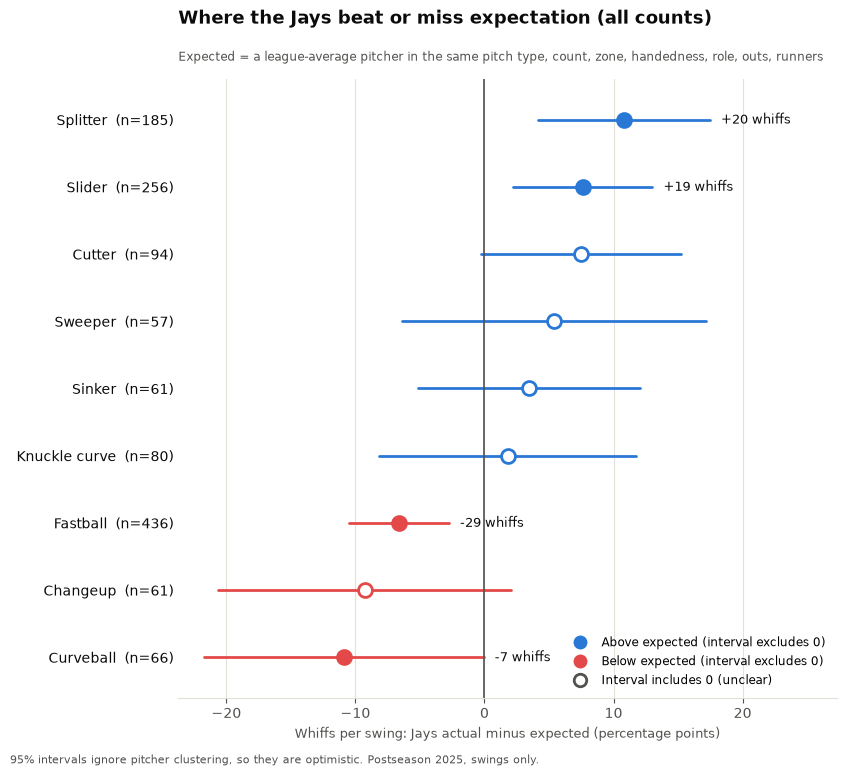

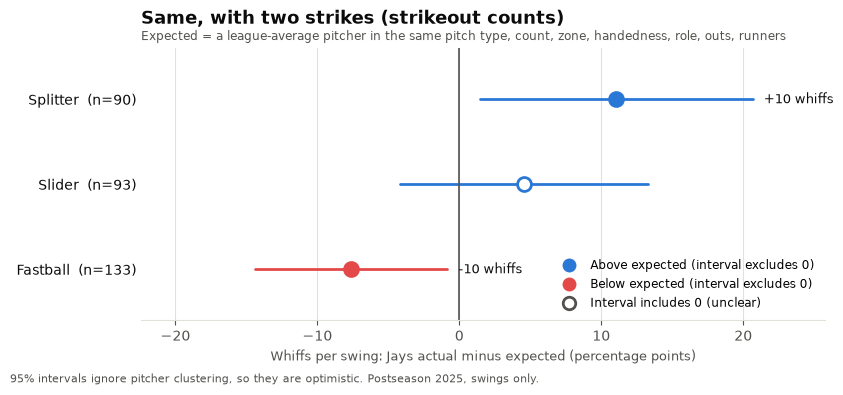

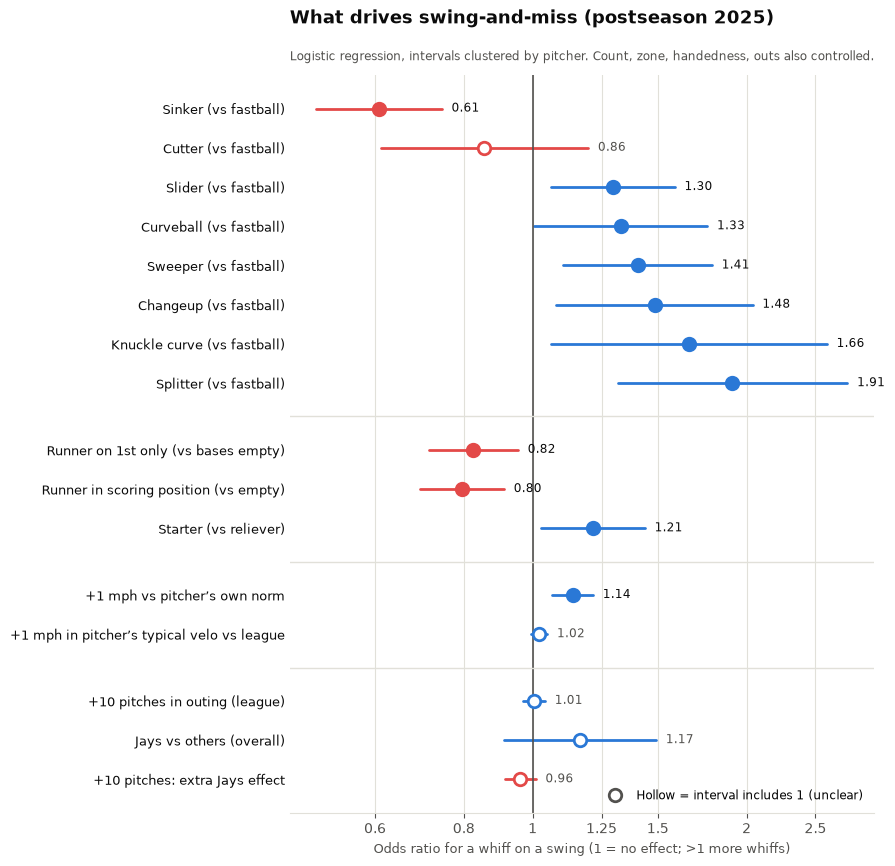

In [24]:
from matplotlib.lines import Line2D

BLUE, RED = '#2a78d6', '#e34948'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
PT = {'FF':'Fastball','SI':'Sinker','FC':'Cutter','SL':'Slider','ST':'Sweeper',
      'CU':'Curveball','KC':'Knuckle curve','CH':'Changeup','FS':'Splitter'}

def clean_axes(ax):
    for s in ['top','right','left']: ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    ax.tick_params(axis='y', length=0, colors=INK); ax.tick_params(axis='x', colors=MUTED)
    ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)

# ---- Plot A: Jays actual vs expected whiff rate by pitch type ----
def oe_plot(rows, title, min_n=30):
    j = rows.copy(); j['p_exp'] = fit_league.predict(j)
    g = j.groupby('pitch_type').agg(n=('whiff','size'), obs=('whiff','sum'), exp=('p_exp','sum'),
                                    var=('p_exp', lambda p: (p*(1-p)).sum()))
    g['diff_pp'] = (g['obs']-g['exp'])/g['n']*100
    g['half'] = 1.96*np.sqrt(g['var'])/g['n']*100
    g = g[g['n'] >= min_n].sort_values('diff_pp')
    fig, ax = plt.subplots(figsize=(8.5, 0.62*len(g)+2.0))
    for yi, (pt, r) in enumerate(g.iterrows()):
        sig = abs(r.diff_pp) > r.half
        c = BLUE if r.diff_pp > 0 else RED
        ax.plot([r.diff_pp-r.half, r.diff_pp+r.half], [yi, yi], color=c, lw=2, solid_capstyle='round')
        ax.plot(r.diff_pp, yi, 'o', ms=10, mfc=c if sig else 'white', mec=c, mew=2, zorder=3)
        if sig:
            ax.annotate(f"{r.obs-r.exp:+.0f} whiffs", (r.diff_pp+r.half, yi), xytext=(8,0),
                        textcoords='offset points', va='center', fontsize=9, color=INK)
    ax.axvline(0, color=MUTED, lw=1.2)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{PT.get(p,p)}  (n={int(n)})" for p, n in zip(g.index, g['n'])], fontsize=10)
    ax.set_ylim(-0.6, len(g)-0.4)
    ax.set_xlabel('Whiffs per swing: Jays actual minus expected (percentage points)', color=MUTED, fontsize=9)
    clean_axes(ax)
    lo, hi = ax.get_xlim(); m = max(abs(lo), abs(hi)); ax.set_xlim(-m, m*1.15)
    ax.text(0, 1.09, title, transform=ax.transAxes, fontsize=13, fontweight='bold', color=INK)
    ax.text(0, 1.03, 'Expected = a league-average pitcher in the same pitch type, count, zone, '
            'handedness, role, outs, runners', transform=ax.transAxes, fontsize=8.5, color=MUTED)
    ax.legend(handles=[
        Line2D([],[],marker='o',ls='',ms=9,mfc=BLUE,mec=BLUE,label='Above expected (interval excludes 0)'),
        Line2D([],[],marker='o',ls='',ms=9,mfc=RED,mec=RED,label='Below expected (interval excludes 0)'),
        Line2D([],[],marker='o',ls='',ms=9,mfc='white',mec=MUTED,mew=2,label='Interval includes 0 (unclear)')],
        loc='lower right', frameon=False, fontsize=8.5)
    fig.text(0.01, -0.01, '95% intervals ignore pitcher clustering, so they are optimistic. '
             'Postseason 2025, swings only.', fontsize=8, color=MUTED)
    plt.tight_layout(); return fig

jays = model_df[model_df['is_jays'] == 1]
fig_a1 = oe_plot(jays, 'Where the Jays beat or miss expectation (all counts)')
fig_a2 = oe_plot(jays[jays['strikes'] == 2], 'Same, with two strikes (strikeout counts)', min_n=40)

# ---- Plot B: odds ratios from M0 ----
def or_plot(res):
    ci = np.exp(res.conf_int()); ci.columns = ['lo','hi']
    t = ci.join(np.exp(res.params).rename('or'))
    spec = [('Pitch type', PT[n.split('T.')[1].rstrip(']')] + ' (vs fastball)', n)
            for n in t.index if 'pitch_type' in n and 'T.' in n]
    spec += [('Situation','Runner on 1st only (vs bases empty)',[n for n in t.index if 'First only' in n][0]),
             ('Situation','Runner in scoring position (vs empty)',[n for n in t.index if 'Scoring' in n][0]),
             ('Situation','Starter (vs reliever)',[n for n in t.index if 'pitcher_role' in n][0]),
             ('Velocity','+1 mph vs pitcher’s own norm','velo_within'),
             ('Velocity','+1 mph in pitcher’s typical velo vs league','velo_between'),
             ('Pitch count','+10 pitches in outing (league)','pc10'),
             ('Pitch count','Jays vs others (overall)','is_jays'),
             ('Pitch count','+10 pitches: extra Jays effect','pc10:is_jays')]
    spec = [s for s in spec if s[2] in t.index]
    pt_rows = sorted([s for s in spec if s[0]=='Pitch type'], key=lambda s: t.loc[s[2],'or'])
    spec = pt_rows + [s for s in spec if s[0] != 'Pitch type']
    fig, ax = plt.subplots(figsize=(9, 0.42*len(spec)+2.0))
    ypos, last, y = [], None, 0
    for grp, lab, n in spec:
        if last is not None and grp != last: y += 0.7
        last = grp; ypos.append(y); y += 1
    ypos = np.array(ypos)
    for yi, (grp, lab, n) in zip(ypos, spec):
        r = t.loc[n]; sig = (r.lo > 1) or (r.hi < 1); c = BLUE if r['or'] > 1 else RED
        ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=2, solid_capstyle='round')
        ax.plot(r['or'], yi, 'o', ms=9, mfc=c if sig else 'white', mec=c, mew=2, zorder=3)
        ax.annotate(f"{r['or']:.2f}", (r.hi, yi), xytext=(7,0), textcoords='offset points',
                    va='center', fontsize=8.5, color=INK if sig else MUTED)
    ax.axvline(1, color=MUTED, lw=1.2); ax.set_xscale('log')
    ax.set_xticks([0.6,0.8,1,1.25,1.5,2,2.5]); ax.set_xticklabels(['0.6','0.8','1','1.25','1.5','2','2.5'])
    ax.minorticks_off()
    ax.set_yticks(ypos); ax.set_yticklabels([s[1] for s in spec], fontsize=9.5); ax.invert_yaxis()
    for i in range(1, len(spec)):
        if spec[i][0] != spec[i-1][0]: ax.axhline((ypos[i]+ypos[i-1])/2, color=GRID, lw=1)
    clean_axes(ax)
    ax.set_xlabel('Odds ratio for a whiff on a swing (1 = no effect; >1 more whiffs)', color=MUTED, fontsize=9)
    ax.text(0, 1.07, 'What drives swing-and-miss (postseason 2025)', transform=ax.transAxes,
            fontsize=13, fontweight='bold', color=INK)
    ax.text(0, 1.02, 'Logistic regression, intervals clustered by pitcher. Count, zone, handedness, outs also controlled.',
            transform=ax.transAxes, fontsize=8.5, color=MUTED)
    ax.legend(handles=[Line2D([],[],marker='o',ls='',ms=9,mfc='white',mec=MUTED,mew=2,
              label='Hollow = interval includes 1 (unclear)')], loc='lower right', frameon=False, fontsize=8.5)
    plt.tight_layout(); return fig

fig_b = or_plot(res0)
for f, name in [(fig_a1,'fig_oe_all'), (fig_a2,'fig_oe_two_strike'), (fig_b,'fig_or_m0')]:
    f.savefig(f'{name}.png', dpi=200, bbox_inches='tight')

# ---- Jays-specific pitch-count slope (the number the "interaction" row can't give you directly) ----
names = list(res0.params.index)
L = np.zeros(len(names)); L[names.index('pc10')] = 1; L[names.index('pc10:is_jays')] = 1
tt = res0.t_test(L)
est = float(np.squeeze(tt.effect)); lo, hi = np.squeeze(tt.conf_int())
print(f"Jays whiff odds per +10 pitches: OR {np.exp(est):.3f} (95% CI {np.exp(lo):.3f}–{np.exp(hi):.3f}), p = {float(np.squeeze(tt.pvalue)):.3f}")